# Mejores Modelos — SHAP Summary Plots (3 paneles)

Análisis comparativo de los mejores modelos base para cada caso (IFN2/IFN3 × c4/carbono\_bruto4),
comparando versiones **locales** (entrenadas solo con ese inventario) y **globales**
(entrenadas con datos de IFN2+3).

| Caso | Modelos |
|------|---------|
| IFN2 / c4 | LightGBM global, LightGBM local |
| IFN2 / carbono\_bruto4 | CatBoost global, LightGBM global, LightGBM local |
| IFN3 / c4 | LightGBM local, GBDT global |
| IFN3 / carbono\_bruto4 | LightGBM local, CatBoost global |

In [49]:
import os
import re
import gc
import sys
import warnings
from pathlib import Path

import joblib
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator
from IPython.display import Image as IPImage, display as ipy_display

import shap
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from scipy.stats import gaussian_kde
from matplotlib.colors import Normalize
import time

warnings.filterwarnings('ignore')
%matplotlib inline

print('Imports OK')

Imports OK


In [50]:
# =============================================================================
# Clases PyTorch — necesarias para deserializar modelos .joblib
# =============================================================================

def cast_to_str(X):
    return pd.DataFrame(X).astype(str).values


class PyTorchMLPDropout(nn.Module):
    def __init__(self, input_dim, hidden_layer_sizes=(100,), activation='relu',
                 dropout_rate=0.2, use_batchnorm=True):
        super().__init__()
        layers = []
        in_dim = input_dim
        if activation == 'relu':         act_fn = nn.ReLU
        elif activation == 'tanh':       act_fn = nn.Tanh
        elif activation == 'leaky_relu': act_fn = lambda: nn.LeakyReLU(0.1)
        else:                            act_fn = nn.ReLU
        for h in hidden_layer_sizes:
            layers.append(nn.Linear(in_dim, h))
            if use_batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(act_fn())
            if dropout_rate > 0: layers.append(nn.Dropout(dropout_rate))
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class MLPRegressorTorch(BaseEstimator, RegressorMixin):
    def __init__(self, hidden_layer_sizes=(100,), activation='relu', solver='adam',
                 alpha=1e-4, learning_rate_init=1e-3, max_iter=200, batch_size=256,
                 dropout_rate=0.2, use_batchnorm=True, device='cpu', verbose=False):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.activation = activation
        self.solver = solver
        self.alpha = alpha
        self.learning_rate_init = learning_rate_init
        self.max_iter = max_iter
        self.batch_size = batch_size
        self.dropout_rate = dropout_rate
        self.use_batchnorm = use_batchnorm
        self.device = device
        self.verbose = verbose
        self.model_ = None

    def predict(self, X):
        if self.model_ is None:
            raise RuntimeError('Model not fitted')
        self.model_.eval()
        self.model_.to(self.device)
        X_t = torch.tensor(pd.DataFrame(X).values, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            return self.model_(X_t).cpu().numpy().flatten()


import __main__
__main__.cast_to_str = cast_to_str
__main__.PyTorchMLPDropout = PyTorchMLPDropout
__main__.MLPRegressorTorch = MLPRegressorTorch

print('Clases PyTorch OK — spoofing listo')

Clases PyTorch OK — spoofing listo


In [51]:
# =============================================================================
# Rutas y configuración
# =============================================================================

BASE = Path('../../../')

DATA_PATH = BASE / 'data/processed/ifn_entrenamiento_year_agrupado_periodo_completado_2.csv'

# Modelos locales
MODELS_IFN2_C4  = BASE / 'models/artifacts/IFN2/c4/base'
MODELS_IFN2_CB4 = BASE / 'models/artifacts/IFN2/carbono_bruto4/base'
MODELS_IFN3_C4  = BASE / 'models/artifacts/IFN3/c4/base'
MODELS_IFN3_CB4 = BASE / 'models/artifacts/IFN3/carbono_bruto4/base'

# Modelos globales (entrenados con IFN2+3)
MODELS_GLO_C4   = BASE / 'models/artifacts/IFN2-3/c4/base'
MODELS_GLO_CB4  = BASE / 'models/artifacts/IFN2-3/carbono_bruto4/base'

# Salida
OUT_DIR   = BASE / 'figures/mejores_modelos_shap'
CACHE_DIR = OUT_DIR / 'cache'
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# ── Muestras para los SHAP summary plots ──────────────────────────────────────
N_SAMPLE_SHAP = 2000
N_BG_SHAP     = 50
# ─────────────────────────────────────────────────────────────────────────────

MAPA_PENDIENTE   = {
    'muy suave (<5°)': 0, 'suave (5-10°)': 1, 'moderada (10-15°)': 2,
    'fuerte (15-20°)': 3, 'muy fuerte (20-30°)': 4,
    'escarpada (30-50°)': 5, 'extrema (>50°)': 6
}
MAPA_ORIENTACION = {'N': 0, 'NE': 1, 'E': 2, 'SE': 3, 'S': 4, 'SO': 5, 'O': 6, 'NO': 7}

FEATURES_C4 = [
    'especie_id', 'tipo_especie', 'periodo_agrupado', 'radio', 'ocupa',
    'npies_1', 'npies_2', 'npies_5', 'npies_10', 'npies_15', 'npies_20',
    'npies_25', 'npies_30', 'npies_35', 'npies_40', 'npies_45', 'npies_50',
    'npies_55', 'npies_60', 'npies_65', 'npies_70',
    'estado_id', 'fccarb', 'disesp_id', 'modcomb_id', 'nivel2_id', 'tratmasa_id',
    'rocosidad_id', 'orientacion_cat', 'elevacion', 'pendiente_cat', 'martonneidx_id',
    'skt_mean_primavera', 'pr_sum_primavera', 'skt_std_verano', 'skt_std_primavera',
    'pr_sum_otoño', 'skt_mean_verano', 'pr_sum_verano', 'pr_sum_invierno',
    'gndvi_mean_verano', 'ndii_mean_primavera', 'gndvi_std_primavera', 'evi_mean_primavera'
]
FEATURES_CB4 = [
    'especie_id', 'tipo_especie', 'periodo_agrupado', 'radio', 'ocupa',
    'npies_1', 'npies_2', 'npies_5', 'npies_10', 'npies_15', 'npies_20',
    'npies_25', 'npies_30', 'npies_35', 'npies_40', 'npies_45', 'npies_50',
    'npies_55', 'npies_60', 'npies_65', 'npies_70',
    'estado_id', 'fccarb', 'disesp_id', 'modcomb_id', 'nivel2_id', 'tratmasa_id',
    'rocosidad_id', 'orientacion_cat', 'elevacion', 'pendiente_cat', 'martonneidx_id',
    'gndvi_mean_verano', 'ndii_mean_primavera', 'gndvi_std_primavera', 'evi_mean_primavera'
]
VARS_CATEGORICAS = [
    'especie_id', 'tipo_especie', 'estado_id', 'disesp_id',
    'modcomb_id', 'nivel2_id', 'tratmasa_id', 'rocosidad_id',
    'martonneidx_id', 'orientacion_cat', 'pendiente_cat'
]

# Variables categóricas con orden significativo → color = valor real (no carbono medio)
VARS_ORDINALES = {'rocosidad_id', 'martonneidx_id', 'estado_id', 'tratmasa_id', 'pendiente_cat', 'tipo_especie'}

# Casos a analizar
# Modelos locales: evaluados sobre el test split del inventario correspondiente
# Modelos globales: evaluados sobre su PROPIO test split IFN2+3 (ifn_filter='')
CASOS = [
    {
        'titulo'    : 'NFI2 / c4',
        'target'    : 'c4',
        'unit'      : 'tC/ha',
        'ifn_filter': '2',
        'features'  : FEATURES_C4,
        'modelos'   : [
            {'label': 'LightGBM local (NFI2)', 'path': MODELS_IFN2_C4 / 'LightGBM.joblib', 'name': 'LightGBM_local', 'out_key': 'IFN2_c4_local'},
        ],
        'cache_key' : 'ifn2_c4',
        'out_key'   : 'IFN2_c4_local',
    },
    {
        'titulo'    : 'NFI2 / carbono\_bruto4',
        'target'    : 'carbono_bruto4',
        'unit'      : 'tC',
        'ifn_filter': '2',
        'features'  : FEATURES_CB4,
        'modelos'   : [
            {'label': 'LightGBM local (NFI2)', 'path': MODELS_IFN2_CB4 / 'LightGBM.joblib', 'name': 'LightGBM_local', 'out_key': 'IFN2_cb4_local'},
        ],
        'cache_key' : 'ifn2_cb4',
        'out_key'   : 'IFN2_cb4_local',
    },
    {
        'titulo'    : 'NFI3 / c4',
        'target'    : 'c4',
        'unit'      : 'tC/ha',
        'ifn_filter': '3',
        'features'  : FEATURES_C4,
        'modelos'   : [
            {'label': 'LightGBM local (NFI3)', 'path': MODELS_IFN3_C4 / 'LightGBM.joblib', 'name': 'LightGBM_local', 'out_key': 'IFN3_c4_local'},
        ],
        'cache_key' : 'ifn3_c4',
        'out_key'   : 'IFN3_c4_local',
    },
    {
        'titulo'    : 'NFI3 / carbono\_bruto4',
        'target'    : 'carbono_bruto4',
        'unit'      : 'tC',
        'ifn_filter': '3',
        'features'  : FEATURES_CB4,
        'modelos'   : [
            {'label': 'LightGBM local (NFI3)', 'path': MODELS_IFN3_CB4 / 'LightGBM.joblib', 'name': 'LightGBM_local', 'out_key': 'IFN3_cb4_local'},
        ],
        'cache_key' : 'ifn3_cb4',
        'out_key'   : 'IFN3_cb4_local',
    },
    {
        'titulo'    : 'NFI2+3 / c4',
        'target'    : 'c4',
        'unit'      : 'tC/ha',
        'ifn_filter': '',
        'features'  : FEATURES_C4,
        'modelos'   : [
            {'label': 'LightGBM global (NFI2+3)', 'path': MODELS_GLO_C4 / 'LightGBM.joblib', 'name': 'LightGBM_global', 'out_key': 'IFN23_c4'},
            {'label': 'GBDT global (NFI2+3)',      'path': MODELS_GLO_C4 / 'GBDT.joblib',     'name': 'GBDT_global',     'out_key': 'IFN23_c4'},
        ],
        'cache_key' : 'ifn23_c4',
        'out_key'   : 'IFN23_c4',
    },
    {
        'titulo'    : 'NFI2+3 / carbono\_bruto4',
        'target'    : 'carbono_bruto4',
        'unit'      : 'tC',
        'ifn_filter': '',
        'features'  : FEATURES_CB4,
        'modelos'   : [
            {'label': 'CatBoost global (NFI2+3)', 'path': MODELS_GLO_CB4 / 'CatBoost.joblib', 'name': 'CatBoost_global', 'out_key': 'IFN23_cb4'},
            {'label': 'LightGBM global (NFI2+3)', 'path': MODELS_GLO_CB4 / 'LightGBM.joblib', 'name': 'LightGBM_global', 'out_key': 'IFN23_cb4'},
        ],
        'cache_key' : 'ifn23_cb4',
        'out_key'   : 'IFN23_cb4',
    },
]

print(f'Casos: {len(CASOS)}')
print(f'Salida: {OUT_DIR}')
print(f'Caché:  {CACHE_DIR}')
print(f'Muestras SHAP: {N_SAMPLE_SHAP}')


Casos: 6
Salida: ../../../figures/mejores_modelos_shap
Caché:  ../../../figures/mejores_modelos_shap/cache
Muestras SHAP: 2000


## Tratamiento de variables categóricas en el análisis SHAP

Las variables categóricas se codifican con **One-Hot Encoding (OHE)** antes de entrar al modelo,
generando una columna binaria por cada categoría. En los gráficos SHAP, los valores de cada variable
se **reagrupan** sumando las contribuciones SHAP de todas sus columnas OHE (etiqueta con `*`).

El **color** de cada punto en el beeswarm y violín indica el valor de la variable en esa muestra,
pero su interpretación varía según el tipo de variable:

### Variables agrupadas ordinales — color = valor real de la variable
El valor numérico tiene un orden significativo: un número mayor implica mayor intensidad del fenómeno.

| Variable | Escala |
|---|---|
| `estado_id*` | 1 = Repoblado → 4 = Fustal (madurez del bosque) |
| `rocosidad_id*` | 1 = Sin pedregosidad → 5 = Roquedo |
| `martonneidx_id*` | 1 = Zona árida → 6 = Zona perhúmeda |
| `tratmasa_id*` | 1 = Monte alto → 3 = Monte bajo |
| `tipo_especie*` | 0 = Conífera (azul), 1 = Frondosa (rojo) — binaria, color directo |

### Variables agrupadas nominales — color = carbono medio del dataset para esa categoría
El valor numérico es un identificador sin orden intrínseco. El color refleja el carbono medio
observado en el dataset para la categoría concreta de cada muestra (calculado sobre todos los datos
antes del split train/test).

| Variable | Descripción |
|---|---|
| `especie_id*` | Especie arbórea (OHE con ~190 categorías) |
| `disesp_id*` | Distribución espacial de la masa |
| `modcomb_id*` | Modelo de combustible (13 tipos) |
| `nivel2_id*` | Nivel morfoestructural del monte |
| `orientacion_cat*` | Orientación cardinal (N/NE/E/SE/S/SO/O/NO) — circular, sin orden lineal |
| `pendiente_cat*` | Clase de pendiente — ordinal en campo, pero tratada como nominal por ser OHE |

### Variable especial: `npies* (Densidad)`
Agrupa las 16 columnas `npies_1` a `npies_70` (número de pies por hectárea por clase diamétrica).
El color es la **suma de los valores normalizados por columna** [0,1]: cada clase diamétrica
contribuye por igual, evitando que `npies_1` (siempre el mayor por ser acumulativo) domine el color.

### Variables continuas — color = valor real normalizado
El resto de variables (`elevacion`, `radio`, `ocupa`, `fccarb`, `periodo_agrupado`, variables
climáticas y de teledetección) usan directamente su valor normalizado como color.


In [52]:
# =============================================================================
# Funciones auxiliares
# =============================================================================

def get_feature_names(preprocessor):
    import math

    def _is_nan(v):
        try: return math.isnan(v)
        except: return False

    try:
        return list(preprocessor.get_feature_names_out())
    except Exception:
        names = []
        for name, step, cols in preprocessor.transformers_:
            if name == 'remainder' and step == 'drop':
                continue
            # Detectar columnas eliminadas por SimpleImputer (statistics_ = NaN
            # para columnas completamente vacías en entrenamiento)
            surviving = list(cols)
            if isinstance(step, Pipeline):
                for _, est in step.steps:
                    if hasattr(est, 'statistics_'):
                        surviving = [c for c, v in zip(surviving, est.statistics_)
                                     if not _is_nan(v)]
                        break
            s = step.steps[-1][1] if isinstance(step, Pipeline) else step
            if isinstance(s, OneHotEncoder) and hasattr(s, 'categories_'):
                for col, cats in zip(surviving, s.categories_):
                    names.extend([f'{col}_{c}' for c in cats])
            else:
                names.extend(surviving)
        return names


def compute_shap(pipeline, X_raw, X_bg_raw, model_name):
    preprocessor = pipeline.named_steps['preprocessor']
    model = pipeline.named_steps['regressor']

    feat_names = get_feature_names(preprocessor)
    X_trans = preprocessor.transform(X_raw)
    if X_trans.shape[1] != len(feat_names):
        feat_names = [f'f_{i:03d}' for i in range(X_trans.shape[1])]
    X_df = pd.DataFrame(X_trans, columns=feat_names)

    tree_types = ['XGBoost', 'LightGBM', 'CatBoost', 'Random_Forest', 'GBDT', 'BaggedDT', 'AdaBoost']
    use_tree = any(t in model_name for t in tree_types)

    if use_tree:
        try:
            explainer = shap.TreeExplainer(model)
            shap_vals = explainer.shap_values(X_df)
            X_used_df = X_df
            X_used_raw = X_raw
        except Exception:
            use_tree = False

    if not use_tree:
        bg_trans = preprocessor.transform(X_bg_raw)
        bg = shap.kmeans(pd.DataFrame(bg_trans, columns=feat_names), 10)
        n = min(100, len(X_df))
        X_used_df = X_df.iloc[:n]
        X_used_raw = X_raw.iloc[:n]
        explainer = shap.KernelExplainer(model.predict, bg)
        shap_vals = explainer.shap_values(X_used_df)

    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]
    base_val = explainer.expected_value
    if isinstance(base_val, (list, np.ndarray)):
        base_val = float(base_val[0])

    return shap_vals, feat_names, X_used_df, X_used_raw, base_val


def load_or_compute_shap(model_path, X_raw, X_bg_raw, model_name, cache_path=None):
    if cache_path is not None:
        cache_path = Path(cache_path)
        if cache_path.exists():
            print(f'[caché] ', end='')
            d = joblib.load(cache_path)
            return d['shap_vals'], d['feat_names'], d['X_trans_df'], d['X_raw_used'], d['base_val']

    pipeline = None
    try:
        pipeline = joblib.load(model_path)
        result = compute_shap(pipeline, X_raw, X_bg_raw, model_name)
    finally:
        if pipeline is not None:
            del pipeline
        gc.collect()

    if cache_path is not None:
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        joblib.dump({
            'shap_vals':  result[0],
            'feat_names': result[1],
            'X_trans_df': result[2],
            'X_raw_used': result[3],
            'base_val':   result[4],
        }, cache_path, compress=3)

    return result


# Colores para etiquetas de variables en los gráficos SHAP
COLOR_VAR_CONT    = '#212121'  # Variables continuas — negro
COLOR_VAR_NPIES   = '#00897b'  # npies* (Densidad) — teal
COLOR_VAR_ORDINAL = '#e65100'  # Categóricas ordinales — naranja oscuro
COLOR_VAR_NOMINAL = '#6a1b9a'  # Categóricas nominales — morado oscuro

# English glosses for Spanish/technical variable names, shown next to the
# original name (e.g. 'npies* (Density)') so tables/figures are self-explanatory
# for non-Spanish-speaking readers. Names not covered here
# are shown as-is (either already in English, or pending confirmation from the
# domain experts before adding a gloss).
VAR_GLOSS = {
    'npies'           : 'Density',
    'especie_id'      : 'Species',
    'tipo_especie'    : 'Species type',
    'ocupa'           : 'Stand occupation ratio',
    'radio'           : 'Plot radius',
    'fccarb'          : 'Canopy cover fraction',
    'rocosidad_id'    : 'Rockiness',
    'orientacion_cat' : 'Aspect category',
    'pendiente_cat'   : 'Slope category',
    'martonneidx_id'  : 'Martonne aridity index',
    'modcomb_id'      : 'Fuel model',
    'tratmasa_id'     : 'Stand treatment',
    'elevacion'       : 'Elevation',
    'periodo_agrupado': 'Grouped period',
    'gndvi_mean_verano'   : 'Mean summer GNDVI',
    'gndvi_std_primavera' : 'Spring GNDVI std. dev.',
    'evi_mean_primavera'  : 'Mean spring EVI',
    'ndii_mean_primavera' : 'Mean spring NDII',
    'skt_mean_verano'     : 'Mean summer skin temperature',
    'skt_mean_primavera'  : 'Mean spring skin temperature',
    'skt_std_verano'      : 'Summer skin-temperature std. dev.',
    'skt_std_primavera'   : 'Spring skin-temperature std. dev.',
    'pr_sum_primavera'    : 'Total spring precipitation',
    'pr_sum_verano'       : 'Total summer precipitation',
    'pr_sum_invierno'     : 'Total winter precipitation',
    'pr_sum_otoño'        : 'Total autumn precipitation',
}

def _gloss(name):
    base = name[:-1] if name.endswith('*') else name
    g = VAR_GLOSS.get(base)
    return f'{name} ({g})' if g else name


def group_shap_explanation(shap_vals, feat_names, X_raw_used, X_trans_df, target_means_maps):
    f_shap, f_data, f_names, f_colors = [], [], [], []
    processed = set()

    npies_idx = [i for i, f in enumerate(feat_names) if f.startswith('npies')]
    if npies_idx:
        f_shap.append(np.sum(shap_vals[:, npies_idx], axis=1))
        npies_cols = [c for c in X_raw_used.columns if 'npies' in c]
        npies_df = X_raw_used[npies_cols].astype(float)
        col_min = npies_df.min(); col_max = npies_df.max()
        npies_norm = (npies_df - col_min) / (col_max - col_min + 1e-12)
        f_data.append(npies_norm.sum(axis=1).values)
        f_names.append(_gloss('npies*'))
        f_colors.append(COLOR_VAR_NPIES)
        processed.update(npies_idx)

    for cat in VARS_CATEGORICAS:
        idx = [
            i for i, f in enumerate(feat_names)
            if (f == cat or f.startswith(cat + '_') or f.startswith(cat + '.'))
            and i not in processed
        ]
        if not idx:
            continue
        f_shap.append(np.sum(shap_vals[:, idx], axis=1))
        if cat in X_raw_used.columns:
            if cat in VARS_ORDINALES:
                f_data.append(X_raw_used[cat].values.astype(float))
                f_colors.append(COLOR_VAR_ORDINAL)
            else:
                mapping = target_means_maps.get(cat, {})
                f_data.append(np.array([mapping.get(v, 0.0) for v in X_raw_used[cat].values]))
                f_colors.append(COLOR_VAR_NOMINAL)
        else:
            f_data.append(np.zeros(shap_vals.shape[0]))
            f_colors.append(COLOR_VAR_NOMINAL)
        f_names.append(_gloss(f'{cat}*'))
        processed.update(idx)

    for i, fname in enumerate(feat_names):
        if i in processed:
            continue
        f_shap.append(shap_vals[:, i])
        if fname in X_raw_used.columns:
            f_data.append(X_raw_used[fname].values)
        else:
            f_data.append(X_trans_df.iloc[:, i].values)
        f_names.append(_gloss(fname))
        f_colors.append(COLOR_VAR_CONT)

    return np.column_stack(f_shap), np.column_stack(f_data), f_names, f_colors


print('Funciones auxiliares OK')

# Alias para compatibilidad con sección de summary plots
group_shap = group_shap_explanation


Funciones auxiliares OK


In [53]:
# Colormap SHAP por defecto (azul=Low, rojo=High)
try:
    import shap as _shap_mod
    CMAP_FEAT = _shap_mod.plots.colors.red_blue
except Exception:
    CMAP_FEAT = mpl.colors.LinearSegmentedColormap.from_list(
        'shap_feat', ['#3288bd', '#ffffbf', '#d53e4f'], N=256
    )

COLOR_BAR    = '#1a7e5c'
COLOR_VIOLIN = '#2fa56a'


def _draw_violin_gradient(ax, x_r, d_n, y_center, cmap, grad=None):
    """Fills a violin shape with a horizontal colormap gradient via imshow + clip."""
    from matplotlib.patches import PathPatch
    from matplotlib.path import Path as MplPath

    top   = np.column_stack([x_r,        y_center + d_n])
    bot   = np.column_stack([x_r[::-1],  y_center - d_n[::-1]])
    verts = np.vstack([top, bot, top[:1]])
    codes = ([MplPath.MOVETO]
             + [MplPath.LINETO] * (len(verts) - 2)
             + [MplPath.CLOSEPOLY])
    path  = MplPath(verts, codes)
    patch = PathPatch(path, transform=ax.transData, facecolor='none', edgecolor='none')
    ax.add_patch(patch)

    if grad is None:
        grad = np.linspace(0, 1, len(x_r)).reshape(1, -1)
    lo, hi = x_r[0], x_r[-1]
    im = ax.imshow(
        grad, aspect='auto', cmap=cmap,
        extent=[lo, hi, y_center - 0.43, y_center + 0.43],
        origin='lower', zorder=2, alpha=0.85
    )
    im.set_clip_path(patch)


def _compute_gradient(shap_vals, feat_vals, x_r):
    """Color del violín en cada posición X = promedio normalizado del valor de
    feature de las muestras que caen en ese bin SHAP. Igual que la librería SHAP."""
    f_min, f_max = feat_vals.min(), feat_vals.max()
    if f_max - f_min < 1e-10:
        return np.full((1, len(x_r)), 0.5)
    feat_norm = (feat_vals - f_min) / (f_max - f_min)
    n = len(x_r)
    lo, hi = x_r[0], x_r[-1]
    span = hi - lo + 1e-12
    # Asignar cada muestra al bin más cercano del eje x_r
    idx = np.clip(np.round((shap_vals - lo) / span * (n - 1)).astype(int), 0, n - 1)
    bin_colors  = np.zeros(n)
    bin_weights = np.zeros(n)
    np.add.at(bin_colors,  idx, feat_norm)
    np.add.at(bin_weights, idx, 1.0)
    valid = bin_weights > 0
    if valid.sum() == 0:
        return np.linspace(0, 1, n).reshape(1, -1)
    bin_colors[valid] /= bin_weights[valid]
    # Interpolar bins vacíos con vecino más cercano
    if valid.sum() < n:
        xp = np.where(valid)[0].astype(float)
        fp = bin_colors[valid]
        for j in np.where(~valid)[0]:
            nearest = xp[np.argmin(np.abs(xp - j))]
            bin_colors[j] = fp[int(np.where(xp == nearest)[0][0])]
    return bin_colors.reshape(1, -1)


def _draw_section(fig, gs_row, names_s, sv_s, dv_s, imp_s, rng, show_xlabel, unit='', var_colors=None):
    """Draw one section (bar + violin + beeswarm) into a GridSpec row."""
    n_s = len(names_s)
    y_s = np.arange(n_s)

    ax1 = fig.add_subplot(gs_row[0])
    ax2 = fig.add_subplot(gs_row[1])
    ax3 = fig.add_subplot(gs_row[2])

    # Bar
    ax1.barh(y_s, imp_s, color=COLOR_BAR, height=0.55, zorder=2)
    ax1.set_yticks(y_s)
    ax1.set_yticklabels(names_s, fontsize=8.5, fontweight='bold')
    if var_colors is not None:
        for tick, col in zip(ax1.get_yticklabels(), var_colors):
            tick.set_color(col)
    ax1.tick_params(axis='x', labelsize=7.5)
    ax1.spines[['top', 'right']].set_visible(False)
    ax1.axvline(0, color='black', linewidth=0.6)
    ax1.grid(axis='x', alpha=0.25, zorder=0)
    ax1.set_ylim(-0.5, n_s - 0.5)
    if show_xlabel:
        ax1.set_xlabel(
            f'mean(|SHAP value|) ({unit})\n(average impact on\nmagnitude of model output)',
            fontsize=8
        )

    # Violin con gradiente de colormap
    for i in range(n_s):
        vals = sv_s[:, i]
        if np.std(vals) < 1e-8:
            ax2.scatter([vals[0]], [y_s[i]], color=COLOR_VIOLIN, s=12, zorder=3)
            continue
        try:
            kde = gaussian_kde(vals, bw_method=0.4)
            lo  = vals.min() - 0.01 * abs(vals.max() - vals.min())
            hi  = vals.max() + 0.01 * abs(vals.max() - vals.min())
            x_r = np.linspace(lo, hi, 200)
            den = kde(x_r)
            d_n = den / den.max() * 0.42
            feat_vals_i = dv_s[:, i]
            grad_i = _compute_gradient(vals, feat_vals_i, x_r)
            _draw_violin_gradient(ax2, x_r, d_n, y_s[i], CMAP_FEAT, grad=grad_i)
            ax2.plot(x_r, y_s[i] - d_n, color='white', linewidth=0.3, alpha=0.4)
            ax2.plot(x_r, y_s[i] + d_n, color='white', linewidth=0.3, alpha=0.4)
        except Exception:
            pass
    ax2.axvline(0, color='black', linewidth=0.7, zorder=4)
    ax2.set_yticks(y_s)
    ax2.set_yticklabels([])
    ax2.tick_params(axis='x', labelsize=7)
    ax2.spines[['top', 'right']].set_visible(False)
    ax2.grid(axis='x', alpha=0.2, zorder=0)
    ax2.set_ylim(-0.5, n_s - 0.5)
    if show_xlabel:
        ax2.set_xlabel(f'SHAP value ({unit})\n(impact on model output)', fontsize=8)

    # Beeswarm
    for i in range(n_s):
        vals      = sv_s[:, i]
        feat_vals = dv_s[:, i]
        f_min, f_max = feat_vals.min(), feat_vals.max()
        feat_norm = (feat_vals - f_min) / (f_max - f_min + 1e-12)
        jitter_y  = np.clip(rng.standard_normal(len(vals)) * 0.17, -0.38, 0.38)
        ax3.scatter(vals, y_s[i] + jitter_y, c=feat_norm, cmap=CMAP_FEAT,
                    s=6, alpha=0.65, linewidths=0, zorder=3)
    ax3.axvline(0, color='black', linewidth=0.7, zorder=2)
    ax3.set_yticks(y_s)
    ax3.set_yticklabels([])
    ax3.tick_params(axis='x', labelsize=7)
    ax3.spines[['top', 'right']].set_visible(False)
    ax3.grid(axis='x', alpha=0.2, zorder=0)
    ax3.set_ylim(-0.5, n_s - 0.5)
    if show_xlabel:
        ax3.set_xlabel(f'SHAP value ({unit})\n(impact on model output)', fontsize=8)

    return ax1, ax2, ax3


def plot_3panel_summary(shap_g, data_g, names_g, title, save_path, top_n=12, n_top_split=2, unit='', var_colors=None):
    """
    3-panel SHAP summary con dos secciones:
      - Superior: top n_top_split caracteristicas (escala X propia)
      - Inferior: caracteristicas restantes (escala X propia)
    Violin coloreado con gradiente. Colorbar incrustada en beeswarm inferior.
    """
    from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

    shap_clean = np.nan_to_num(shap_g, nan=0.0, posinf=0.0, neginf=0.0)
    data_clean = np.nan_to_num(data_g, nan=0.0, posinf=0.0, neginf=0.0)

    importances = np.mean(np.abs(shap_clean), axis=0)
    n_avail    = len(importances)
    actual_top = min(top_n, n_avail)
    top_idx    = np.argsort(importances)[::-1][:actual_top][::-1]
    names  = [names_g[i] for i in top_idx]
    sv     = shap_clean[:, top_idx]
    dv     = data_clean[:, top_idx]
    imp    = importances[top_idx]
    colors = [var_colors[i] for i in top_idx] if var_colors is not None else None
    n_feat = actual_top

    n_top  = min(n_top_split, n_feat)
    n_rest = n_feat - n_top

    # Seccion superior: los n_top mas importantes (indices finales)
    names_top  = names[n_rest:]
    sv_top     = sv[:, n_rest:]
    dv_top     = dv[:, n_rest:]
    imp_top    = imp[n_rest:]
    colors_top = colors[n_rest:] if colors is not None else None

    # Seccion inferior: los n_rest restantes
    names_rest  = names[:n_rest]
    sv_rest     = sv[:, :n_rest]
    dv_rest     = dv[:, :n_rest]
    imp_rest    = imp[:n_rest]
    colors_rest = colors[:n_rest] if colors is not None else None

    h_top  = max(0.9, n_top  * 0.40 + 0.25)
    h_rest = max(2.2, n_rest * 0.29 + 0.35)

    fig = plt.figure(figsize=(5.5, h_top + h_rest + 0.3))

    gs = GridSpec(2, 1, figure=fig,
                  height_ratios=[h_top, h_rest],
                  hspace=0.35)

    col_ratios = [1, 1.4, 1.4]
    gs_top = GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[0],
                                     width_ratios=col_ratios, wspace=0.08)
    gs_bot = GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[1],
                                     width_ratios=col_ratios, wspace=0.08)

    rng = np.random.default_rng(42)

    _draw_section(fig, gs_top, names_top, sv_top, dv_top, imp_top, rng, show_xlabel=False, unit=unit, var_colors=colors_top)
    _, _, ax3_bot = _draw_section(fig, gs_bot, names_rest, sv_rest, dv_rest, imp_rest, rng,
                                   show_xlabel=True, unit=unit, var_colors=colors_rest)

    # Colorbar incrustada en beeswarm inferior, abajo a la derecha
    # Usamos ax.inset_axes (coordenadas en axes-space) en lugar de
    # mpl_toolkits inset_axes para evitar desplazamiento en PDF.
    sm = mpl.cm.ScalarMappable(cmap=CMAP_FEAT, norm=Normalize(0, 1))
    sm.set_array([])
    axins = ax3_bot.inset_axes([0.93, 0.03, 0.04, 0.33])
    cbar = fig.colorbar(sm, cax=axins)
    cbar.set_ticks([0.02, 0.98])
    cbar.set_ticklabels(['Low', 'High'], fontsize=7.5)
    cbar.outline.set_visible(False)
    axins.yaxis.set_ticks_position('left')
    axins.yaxis.set_label_position('left')

    # Leyenda de tipos de variables
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=COLOR_VAR_NPIES,   label='npies*: normalized sum by diameter class'),
        Patch(facecolor=COLOR_VAR_ORDINAL, label='Ordinal cat.*: color = real variable value'),
        Patch(facecolor=COLOR_VAR_NOMINAL, label='Nominal cat.*: color = dataset mean carbon'),
        Patch(facecolor=COLOR_VAR_CONT,    label='Continuous: color = normalized real value'),
    ]
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.subplots_adjust(bottom=0.24)
    fig.legend(handles=legend_elements, loc='lower center',
               prop={'size': 6.5, 'weight': 'bold'},
               ncol=2, framealpha=0.95, edgecolor='#aaaaaa',
               bbox_to_anchor=(0.5, 0.04), borderpad=0.8)
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()
    plt.close()
    print(f'  -> {save_path}')



print('Funciones de plot OK')


Funciones de plot OK


In [54]:
def load_ifn_sample(target, features, ifn_filter, n_sample=300, n_bg=50, seed=42):
    """Carga y filtra datos IFN, devuelve muestra SHAP y background."""
    df = pd.read_csv(DATA_PATH)
    df['ifn_str'] = df['ifn_id'].astype(str)
    if ifn_filter:
        df = df[df['ifn_str'].str.contains(ifn_filter)].copy()

    # Mapeos de categorías ordinales
    if 'pendiente_cat'   in df.columns: df['pendiente_cat']   = df['pendiente_cat'].map(MAPA_PENDIENTE)
    if 'orientacion_cat' in df.columns: df['orientacion_cat'] = df['orientacion_cat'].map(MAPA_ORIENTACION)

    # Filtros de calidad (igual que en entrenamiento)
    df = df[(df[target].notna()) & (df[target] != 0)].copy()
    if 'c' in df.columns:
        df = df[(df['c'].isna()) | (df['c'] < df[target])].copy()
    df = df[~(df['fccarb'].notna() & (df['fccarb'] < 20))].copy()

    # Target means por categoría (para color en group_shap)
    tm = {col: df.groupby(col)[target].mean().to_dict()
          for col in VARS_CATEGORICAS if col in df.columns}

    present = [c for c in features if c in df.columns]
    X = df[present].copy().astype('float32')
    y = df[target].copy().astype('float32')

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    _, te_idx = next(gss.split(X, y, groups=df['parcela_id']))
    X_test = X.iloc[te_idx].copy()

    rng = np.random.default_rng(seed)
    X_sample = X_test.sample(min(n_sample, len(X_test)), random_state=seed)
    X_bg     = X_test.sample(min(n_bg,     len(X_test)), random_state=seed+1)

    lbl = ifn_filter if ifn_filter else '2+3'
    print(f'  IFN{lbl} / {target}: {len(X_test):,} test | muestra={len(X_sample)} bg={len(X_bg)}')
    return X_sample, X_bg, tm


print('Función load_ifn_sample OK')


Función load_ifn_sample OK


---
## Análisis por caso

Para cada caso se computan los SHAP values y se genera el summary plot de 3 paneles
por modelo. Los resultados se guardan en `figures/mejores_modelos_shap/`.


CASO: IFN2 / c4
  IFN2 / c4: 8,324 test | muestra=2000 bg=50

  >>> LightGBM local (IFN2)
[caché] 

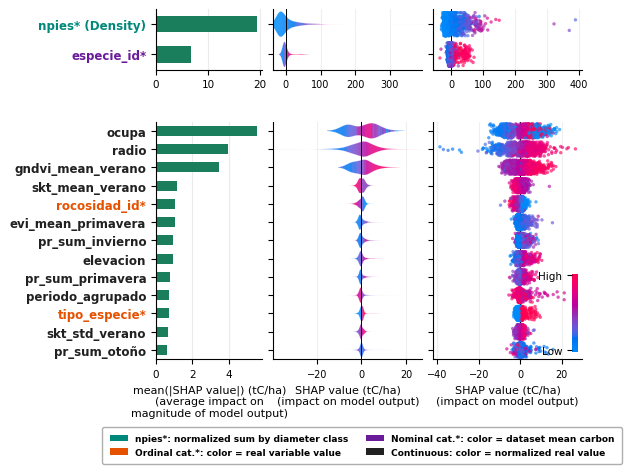

  -> ../../../figures/mejores_modelos_shap/IFN2_c4_local/shap_summary_LightGBM_local_n2000.png

CASO: IFN2 / carbono\_bruto4
  IFN2 / carbono_bruto4: 8,699 test | muestra=2000 bg=50

  >>> LightGBM local (IFN2)
[caché] 

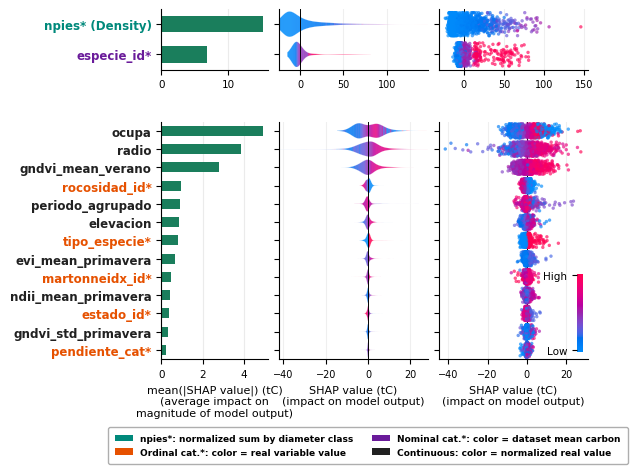

  -> ../../../figures/mejores_modelos_shap/IFN2_cb4_local/shap_summary_LightGBM_local_n2000.png

CASO: IFN3 / c4
  IFN3 / c4: 12,332 test | muestra=2000 bg=50

  >>> LightGBM local (IFN3)
[caché] 

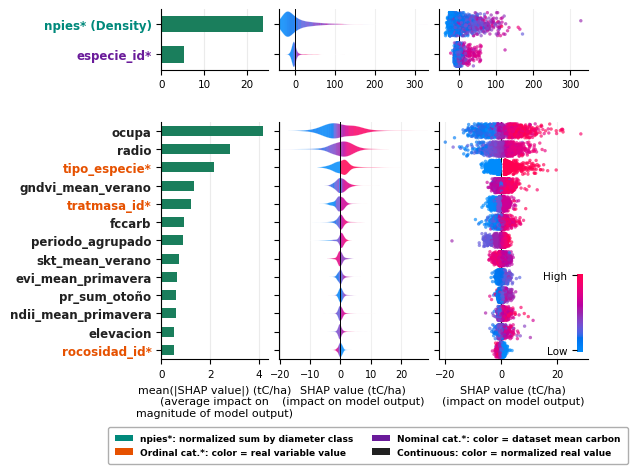

  -> ../../../figures/mejores_modelos_shap/IFN3_c4_local/shap_summary_LightGBM_local_n2000.png

CASO: IFN3 / carbono\_bruto4
  IFN3 / carbono_bruto4: 17,937 test | muestra=2000 bg=50

  >>> LightGBM local (IFN3)
[caché] 

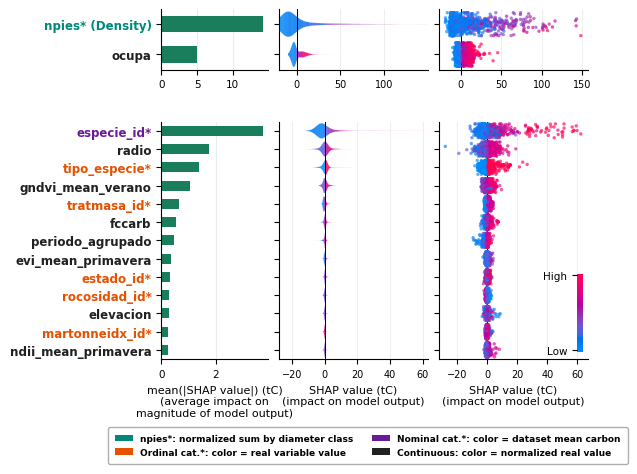

  -> ../../../figures/mejores_modelos_shap/IFN3_cb4_local/shap_summary_LightGBM_local_n2000.png

CASO: IFN2+3 / c4
  IFN2+3 / c4: 20,605 test | muestra=2000 bg=50

  >>> LightGBM global (IFN2+3)
[caché] 

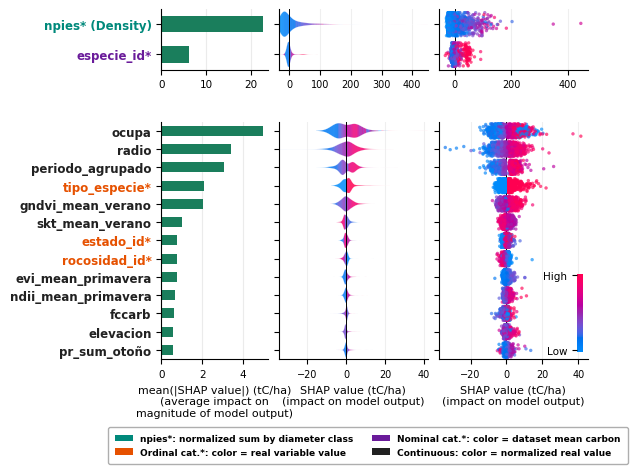

  -> ../../../figures/mejores_modelos_shap/IFN23_c4/shap_summary_LightGBM_global_n2000.png

  >>> GBDT global (IFN2+3)
[caché] 

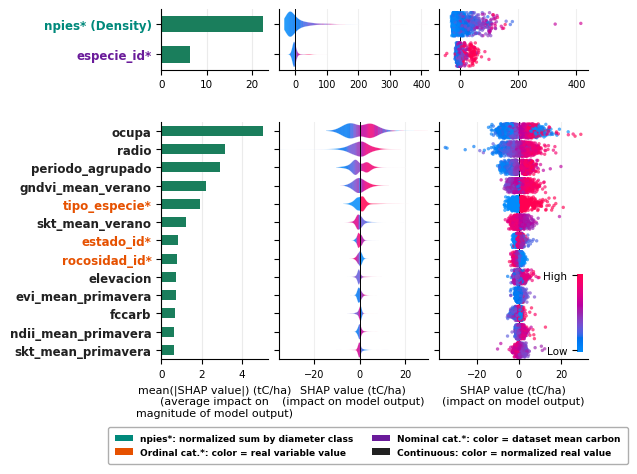

  -> ../../../figures/mejores_modelos_shap/IFN23_c4/shap_summary_GBDT_global_n2000.png

CASO: IFN2+3 / carbono\_bruto4
  IFN2+3 / carbono_bruto4: 26,664 test | muestra=2000 bg=50

  >>> CatBoost global (IFN2+3)
[caché] 

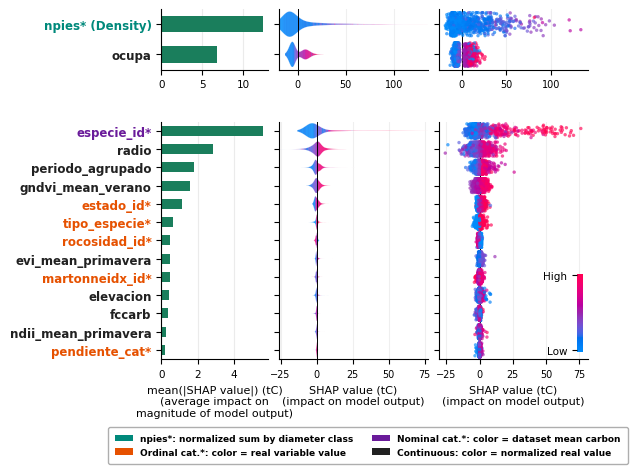

  -> ../../../figures/mejores_modelos_shap/IFN23_cb4/shap_summary_CatBoost_global_n2000.png

  >>> LightGBM global (IFN2+3)
[caché] 

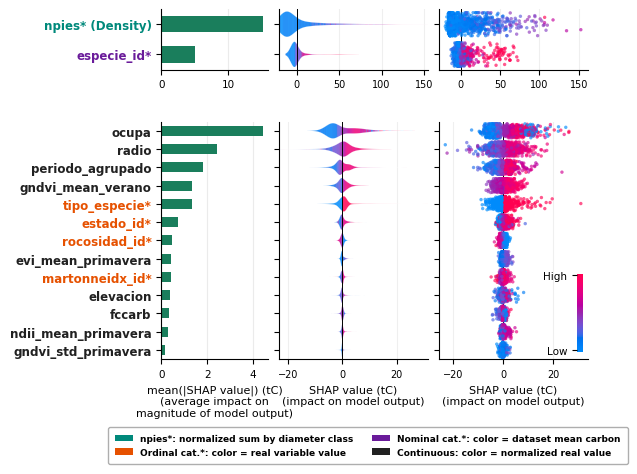

  -> ../../../figures/mejores_modelos_shap/IFN23_cb4/shap_summary_LightGBM_global_n2000.png

Análisis completado.


In [55]:
FORCE_REGEN = True   # True → regenera aunque el PNG ya exista

for caso in CASOS:
    titulo    = caso['titulo']
    target    = caso['target']
    unit      = caso['unit']
    ifn_filt  = caso['ifn_filter']
    features  = caso['features']
    modelos   = caso['modelos']
    cache_key = caso['cache_key']
    out_key   = caso['out_key']

    print(f'\n{"="*65}')
    print(f'CASO: {titulo}')
    print(f'{"="*65}')

    # Cargar datos una sola vez por caso
    X_sample, X_bg, tm = load_ifn_sample(target, features, ifn_filt,
                                          n_sample=N_SAMPLE_SHAP, n_bg=N_BG_SHAP)

    for mod in modelos:
        model_path = mod['path']
        model_name = mod['name']
        label      = mod['label']

        mod_out_key = mod.get('out_key', out_key)
        save_path  = OUT_DIR / mod_out_key / f'shap_summary_{model_name}_n{N_SAMPLE_SHAP}.png'
        cache_path = CACHE_DIR / cache_key / f'{model_name}_n{N_SAMPLE_SHAP}.joblib'

        print(f'\n  >>> {label}')

        if save_path.exists() and not FORCE_REGEN:
            print(f'  [OK] ya existe')
            ipy_display(IPImage(str(save_path)))
            continue

        try:
            sv, fn, Xt, Xr, bv = load_or_compute_shap(
                model_path, X_sample, X_bg, model_name, cache_path=cache_path
            )
            shap_g, data_g, names_g, colors_g = group_shap(sv, fn, Xr, Xt, tm)
            plot_3panel_summary(
                shap_g, data_g, names_g,
                title     = f'{label}  |  {target} ({unit})',
                save_path = save_path,
                top_n     = 15,
                unit      = unit,
                var_colors= colors_g,
            )
        except Exception as e:
            print(f'  ERROR: {e}')
        finally:
            gc.collect()

print('\nAnálisis completado.')


In [56]:
# =============================================================================
# Tabla de posiciones medias (ranking SHAP) por variable, modelo y caso
# Modelos: LightGBM, XGBoost, CatBoost, GBDT, MLP_PyTorch
# Casos:   IFN2/c4, IFN2/cb4, IFN3/c4, IFN3/cb4, IFN2+3/c4, IFN2+3/cb4
# =============================================================================

RANK_MODELS = ['LightGBM', 'XGBoost', 'CatBoost', 'GBDT', 'MLP_PyTorch']

RANK_CASOS = [
    {'label': 'NFI2 / c4',          'target': 'c4',             'ifn': '2', 'features': FEATURES_C4,  'model_dir': MODELS_IFN2_C4,  'cache_key': 'ifn2_c4'},
    {'label': 'NFI2 / carbono_b4',  'target': 'carbono_bruto4', 'ifn': '2', 'features': FEATURES_CB4, 'model_dir': MODELS_IFN2_CB4, 'cache_key': 'ifn2_cb4'},
    {'label': 'NFI3 / c4',          'target': 'c4',             'ifn': '3', 'features': FEATURES_C4,  'model_dir': MODELS_IFN3_C4,  'cache_key': 'ifn3_c4'},
    {'label': 'NFI3 / carbono_b4',  'target': 'carbono_bruto4', 'ifn': '3', 'features': FEATURES_CB4, 'model_dir': MODELS_IFN3_CB4, 'cache_key': 'ifn3_cb4'},
    {'label': 'NFI2+3 / c4',        'target': 'c4',             'ifn': '',  'features': FEATURES_C4,  'model_dir': MODELS_GLO_C4,   'cache_key': 'glo_c4'},
    {'label': 'NFI2+3 / carbono_b4','target': 'carbono_bruto4', 'ifn': '',  'features': FEATURES_CB4, 'model_dir': MODELS_GLO_CB4,  'cache_key': 'glo_cb4'},
]

# Acumular posiciones: caso_label → variable → lista de ranks (una por modelo)
all_ranks = {}

for caso in RANK_CASOS:
    lbl = caso['label']
    print(f'\n── {lbl} ──')

    X_sample, X_bg, tm = load_ifn_sample(
        caso['target'], caso['features'], caso['ifn'],
        n_sample=N_SAMPLE_SHAP, n_bg=N_BG_SHAP
    )

    var_ranks = {}  # variable_name → [rank_modelo1, rank_modelo2, ...]

    for mname in RANK_MODELS:
        model_path = caso['model_dir'] / f'{mname}.joblib'
        if not model_path.exists():
            print(f'  [SKIP] {mname} — modelo no encontrado')
            continue
        cache_path = CACHE_DIR / caso['cache_key'] / f'{mname}_n{N_SAMPLE_SHAP}.joblib'
        try:
            sv, fn, Xt, Xr, bv = load_or_compute_shap(
                model_path, X_sample, X_bg, mname, cache_path=cache_path
            )
            shap_g, _, names_g, _ = group_shap(sv, fn, Xr, Xt, tm)
            mean_abs = np.abs(shap_g).mean(axis=0)
            order = np.argsort(-mean_abs)          # desc → índice 0 = más importante
            for rank_pos, j in enumerate(order, start=1):
                var_ranks.setdefault(names_g[j], []).append(rank_pos)
            print(f'  [OK] {mname}')
        except Exception as e:
            print(f'  [ERROR] {mname}: {e}')
        finally:
            gc.collect()

    all_ranks[lbl] = var_ranks

# ── Construir DataFrame ──────────────────────────────────────────────────────
caso_labels = [c['label'] for c in RANK_CASOS]
all_vars    = sorted(set(v for cr in all_ranks.values() for v in cr))

df_ranks = pd.DataFrame(index=all_vars, columns=caso_labels, dtype=float)
for lbl, var_ranks in all_ranks.items():
    for var, ranks in var_ranks.items():
        df_ranks.loc[var, lbl] = round(float(np.mean(ranks)), 1)

# Ordenar por rango medio global (más importante primero)
df_ranks.insert(0, 'Mean', df_ranks.mean(axis=1).round(1))
df_ranks = df_ranks.sort_values('Mean')

# ── Mostrar tabla estilizada ─────────────────────────────────────────────────
n_vars = len(df_ranks)
display(
    df_ranks.style
        .format('{:.1f}', na_rep='—')
        .background_gradient(
            cmap='RdYlGn_r',
            subset=caso_labels,
            vmin=1, vmax=n_vars
        )
        .background_gradient(
            cmap='RdYlGn_r',
            subset=['Mean'],
            vmin=1, vmax=n_vars
        )
        .set_caption(
            f'Mean SHAP rank per variable across {len(RANK_MODELS)} models '
            f'(LightGBM, XGBoost, CatBoost, GBDT, MLP)  |  '
            f'n={N_SAMPLE_SHAP} samples  |  rank 1 = most important'
        )
        .set_table_styles([{
            'selector': 'caption',
            'props': [('font-size', '12px'), ('font-weight', 'bold'), ('text-align', 'left')]
        }])
)



── IFN2 / c4 ──
  IFN2 / c4: 8,324 test | muestra=2000 bg=50
[caché]   [OK] LightGBM
[caché]   [OK] XGBoost
[caché]   [OK] CatBoost
[caché]   [OK] GBDT
[caché]   [OK] MLP_PyTorch

── IFN2 / carbono_b4 ──
  IFN2 / carbono_bruto4: 8,699 test | muestra=2000 bg=50
[caché]   [OK] LightGBM
[caché]   [OK] XGBoost
[caché]   [OK] CatBoost
[caché]   [OK] GBDT
[caché]   [OK] MLP_PyTorch

── IFN3 / c4 ──
  IFN3 / c4: 12,332 test | muestra=2000 bg=50
[caché]   [OK] LightGBM
[caché]   [OK] XGBoost
[caché]   [OK] CatBoost
[caché]   [OK] GBDT
[caché]   [OK] MLP_PyTorch

── IFN3 / carbono_b4 ──
  IFN3 / carbono_bruto4: 17,937 test | muestra=2000 bg=50
[caché]   [OK] LightGBM
[caché]   [OK] XGBoost
[caché]   [OK] CatBoost
[caché]   [OK] GBDT
[caché]   [OK] MLP_PyTorch

── IFN2+3 / c4 ──
  IFN2+3 / c4: 20,605 test | muestra=2000 bg=50
[caché]   [OK] LightGBM
[caché]   [OK] XGBoost
[caché]   [OK] CatBoost
[caché]   [OK] GBDT
[caché]   [OK] MLP_PyTorch

── IFN2+3 / carbono_b4 ──
  IFN2+3 / carbono_bruto4:

,Mean,IFN2 / c4,IFN2 / carbono_b4,IFN3 / c4,IFN3 / carbono_b4,IFN2+3 / c4,IFN2+3 / carbono_b4
npies* (Density),1.0,1.0,1.0,1.0,1.0,1.0,1.0
especie_id*,2.2,2.0,2.0,2.2,2.8,2.2,2.2
ocupa,2.9,3.2,3.0,3.0,2.2,2.8,3.0
radio,4.2,4.2,4.2,4.2,4.0,4.2,4.4
gndvi_mean_verano,6.6,6.0,5.0,7.0,7.0,7.8,6.6
tipo_especie*,7.1,11.4,8.8,4.6,5.8,6.0,6.0
periodo_agrupado,8.4,12.8,8.2,10.8,8.6,5.2,5.0
skt_mean_verano,9.5,6.6,—,10.4,—,11.6,—
rocosidad_id*,11.0,8.8,7.6,17.6,12.0,10.6,9.4
fccarb,11.2,—,—,9.0,9.6,13.6,12.4


In [57]:
# =============================================================================
# Exportación LaTeX de las tablas de ranking SHAP
# Requiere haber ejecutado cell-ranking-table (df_ranks) y, en el notebook
# de especies, cell-ranking-abs + cell-ranking-signed (df_pos, df_neg).
# =============================================================================

def _fmt_rank(v):
    """Formatea un rank: entero si .0, si no 1 decimal."""
    if pd.isna(v): return '---'
    return f'{v:.0f}' if v == int(v) else f'{v:.1f}'

def _fmt_shap(v):
    if pd.isna(v): return '---'
    return f'{v:+.3f}'

def _escape(s):
    """Escapa caracteres especiales LaTeX en nombres de variables."""
    return s.replace('_', r'\_').replace('%', r'\%').replace('&', r'\&')

def table_to_latex(df, fmt_fn, caption, label, col_fmt=None,
                   bold_min=True, bold_max=False, unit=''):
    """
    Genera tabla LaTeX en estilo booktabs.
    bold_min: pone en negrita el mínimo de cada columna (para rankings).
    bold_max: pone en negrita el máximo de cada columna (para contribuciones).
    """
    cols = list(df.columns)
    n_cols = 1 + len(cols)  # variable name + data cols

    if col_fmt is None:
        col_fmt = 'l' + 'r' * len(cols)

    lines = []
    lines.append(r'\begin{table}[htbp]')
    lines.append(r'  \centering')
    lines.append(r'  \footnotesize')
    lines.append(f'  \\caption{{{caption}}}')
    lines.append(f'  \\label{{tab:{label}}}')
    lines.append(f'  \\begin{{tabular}}{{{col_fmt}}}')
    lines.append(r'    \toprule')

    # Header
    header_parts = ['Variable']
    for c in cols:
        # Formato de columnas: sustituir / por espacios y añadir salto de línea
        c_tex = c.replace('carbono_b4', 'carb.\\_b4').replace('/', ' /\\\n               ')
        header_parts.append(f'\\textbf{{{_escape(c)}}}')
    lines.append('    ' + ' & '.join(header_parts) + r' \\')
    lines.append(r'    \midrule')

    # Precompute bold targets per column
    bold_vals = {}
    for c in cols:
        col_data = df[c].dropna()
        if len(col_data) == 0: continue
        if bold_min:
            bold_vals[c] = col_data.min()
        elif bold_max:
            bold_vals[c] = col_data.abs().max()

    # Data rows
    for var, row in df.iterrows():
        parts = [_escape(str(var))]
        for c in cols:
            val = row[c]
            cell_str = fmt_fn(val)
            if not pd.isna(val) and c in bold_vals:
                if bold_min and abs(val - bold_vals[c]) < 1e-6:
                    cell_str = f'\\textbf{{{cell_str}}}'
                elif bold_max and abs(abs(val) - bold_vals[c]) < 1e-6:
                    cell_str = f'\\textbf{{{cell_str}}}'
            parts.append(cell_str)
        lines.append('    ' + ' & '.join(parts) + r' \\')

    lines.append(r'    \bottomrule')
    lines.append(r'  \end{tabular}')
    lines.append(r'\end{table}')
    return '\n'.join(lines)


# ── Tabla 1: ranking absoluto ─────────────────────────────────────────────────
print('% ============================================================')
print('% Tabla: Ranking medio de variables por |SHAP|')
print('% ============================================================')
print(table_to_latex(
    df_ranks,
    fmt_fn   = _fmt_rank,
    caption  = 'Mean SHAP rank per variable across LightGBM, XGBoost, CatBoost, GBDT and MLP '
               f'(n={N_SAMPLE_SHAP} samples; rank 1 = most important).',
    label    = 'shap_rank_abs',
    bold_min = True,
))

print()

# ── Tablas 2 y 3: contribuciones con signo (solo si existen) ─────────────────
# Estas se generan en cell-ranking-signed del notebook de especies;
# si están disponibles en este contexto, también se exportan.
for _df, _lbl, _cap, _bmax in [
    (globals().get('df_pos'), 'shap_rank_pos',
     'Variables with positive mean SHAP contribution (averaged across models; '
     'higher = pushes prediction up more).', True),
    (globals().get('df_neg'), 'shap_rank_neg',
     'Variables with negative mean SHAP contribution (averaged across models; '
     'more negative = pushes prediction down more).', True),
]:
    if _df is None:
        continue
    print(f'% ============================================================')
    print(f'% Tabla: {_lbl}')
    print(f'% ============================================================')
    print(table_to_latex(
        _df,
        fmt_fn   = _fmt_shap,
        caption  = _cap,
        label    = _lbl,
        bold_min = False,
        bold_max = _bmax,
    ))
    print()


% ============================================================
% Tabla: Ranking medio de variables por |SHAP|
% ============================================================
\begin{table}[htbp]
  \centering
  \footnotesize
  \caption{Mean SHAP rank per variable across LightGBM, XGBoost, CatBoost, GBDT and MLP (n=2000 samples; rank 1 = most important).}
  \label{tab:shap_rank_abs}
  \begin{tabular}{lrrrrrrr}
    \toprule
    Variable & \textbf{Mean} & \textbf{IFN2 / c4} & \textbf{IFN2 / carbono\_b4} & \textbf{IFN3 / c4} & \textbf{IFN3 / carbono\_b4} & \textbf{IFN2+3 / c4} & \textbf{IFN2+3 / carbono\_b4} \\
    \midrule
    npies* (Density) & \textbf{1} & \textbf{1} & \textbf{1} & \textbf{1} & \textbf{1} & \textbf{1} & \textbf{1} \\
    especie\_id* & 2.2 & 2 & 2 & 2.2 & 2.8 & 2.2 & 2.2 \\
    ocupa & 2.9 & 3.2 & 3 & 3 & 2.2 & 2.8 & 3 \\
    radio & 4.2 & 4.2 & 4.2 & 4.2 & 4 & 4.2 & 4.4 \\
    gndvi\_mean\_verano & 6.6 & 6 & 5 & 7 & 7 & 7.8 & 6.6 \\
    tipo\_especie* & 7.1 & 11.4 & 8.8 &